# Lab 01 - Regression

In [5]:
import numpy as np
import pandas as pd
from ucimlrepo import fetch_ucirepo
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid")

## 1. Implement from scratch

### 1.1. Simple Linear Regression

In [6]:
X = np.array([[1], [2], [3], [4], [5]])
y = np.array([1, 2, 1.3, 3.75, 2.25])
print("X:", X)
print("y:", y)

X: [[1]
 [2]
 [3]
 [4]
 [5]]
y: [1.   2.   1.3  3.75 2.25]


In [7]:
class SimpleLinearRegression:
    def __init__(self):
        self.b0 = 0.0  # Intercept
        self.b1 = 0.0  # Slope

    def fit(self, X, y):
        x_flat = X.flatten()
        x_mean = np.mean(x_flat)
        y_mean = np.mean(y)
        
        # Calculate slope (b1) and intercept (b0)
        self.b1 = np.sum((x_flat - x_mean) * (y - y_mean)) / np.sum((x_flat - x_mean) ** 2)
        self.b0 = y_mean - self.b1 * x_mean

    def predict(self, X):
        return self.b0 + self.b1 * X.flatten()

In [8]:
# TODO: Predicting using SimpleLinearRegression
slr = SimpleLinearRegression()
slr.fit(X, y)
y_pred = slr.predict(X)

print(f"Intercept (b0): {slr.b0:.3f}")
print(f"Slope (b1): {slr.b1:.3f}")
print("Predictions:", y_pred)

Intercept (b0): 0.785
Slope (b1): 0.425
Predictions: [1.21  1.635 2.06  2.485 2.91 ]


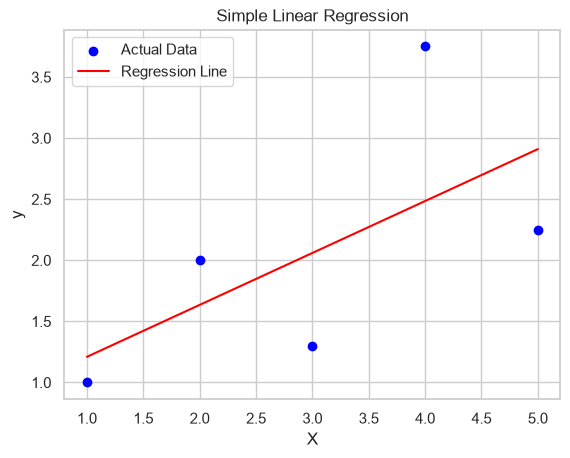

In [9]:
# TODO: Visualizing the results (scatter plot and regression line)
plt.scatter(X, y, color='blue', label='Actual Data')
plt.plot(X, y_pred, color='red', label='Regression Line')
plt.xlabel('X')
plt.ylabel('y')
plt.title('Simple Linear Regression')
plt.legend()
plt.show()

### 1.2 Multiple Linear Regression

In [10]:
X = np.array(
    [
        [1,1,1],
        [1,1,2],
        [1,2,2],
        [1,0,1]
    ]
)

Y = np.array([
    3.25,
    6.5,
    3.5,
    5.0
])

In [11]:
class MultipleLinearRegression:
    def __init__(self):
        self.weights = None

    def fit(self, X, y):
        # Normal Equation: w = (X^T * X)^(-1) * X^T * y
        self.weights = np.linalg.inv(X.T @ X) @ X.T @ y

    def predict(self, X):
        return X @ self.weights

In [12]:
# TODO: Predicting using MultipleLinearRegression
mlr = MultipleLinearRegression()
mlr.fit(X, Y)
Y_pred = mlr.predict(X)

print("Weights (b0, b1, b2):", mlr.weights)
print("Predictions:", Y_pred)

Weights (b0, b1, b2): [ 2.0625 -2.375   3.25  ]
Predictions: [2.9375 6.1875 3.8125 5.3125]


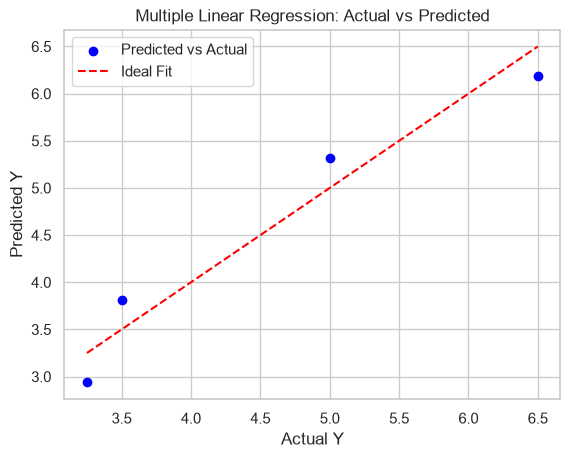

In [13]:
# TODO: VIsualizing the results (scatter plot and regression line)
plt.scatter(Y, Y_pred, color='blue', label='Predicted vs Actual')
plt.plot([Y.min(), Y.max()], [Y.min(), Y.max()], color='red', linestyle='--', label='Ideal Fit')
plt.xlabel('Actual Y')
plt.ylabel('Predicted Y')
plt.title('Multiple Linear Regression: Actual vs Predicted')
plt.legend()
plt.show()

### 1.3 Gradient Descent

In [14]:
# TODO: Implement gradient descent algorithm
def gradient_descent(starting_point, gradient_func, learning_rate, max_iter, tolerance):
    x = starting_point
    history = [x]
    
    for _ in range(max_iter):
        grad = gradient_func(x)
        next_x = x - learning_rate * grad
        history.append(next_x)
        
        if abs(next_x - x) < tolerance:
            x = next_x
            break
        x = next_x
        
    return history, x

In [15]:
def func(x):
    return x**2 - 4*x + 1

def grad_func(x):
    return 2*x - 4


Optimized result: 1.976941569907863


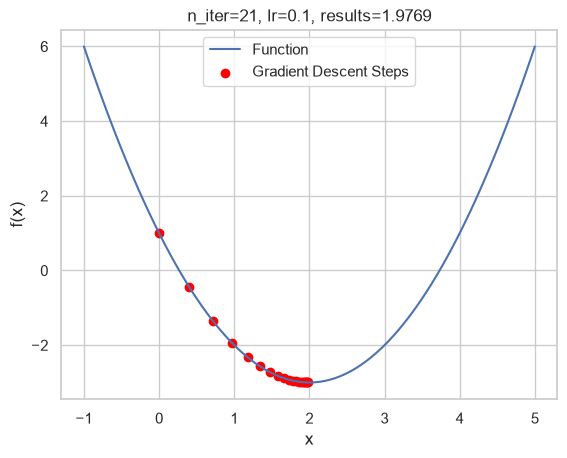

In [16]:
lr = 0.1

history, result = gradient_descent(
    starting_point=0.0,
    gradient_func=grad_func,
    learning_rate=lr,
    max_iter=20,
    tolerance=1e-6
)
print("Optimized result:", result)

history_array = np.array(history)
x_vals = np.linspace(-1, 5, 100)
y_vals = func(x_vals)

plt.plot(x_vals, y_vals, label='Function')
plt.scatter(history_array, func(history_array), color='red', label='Gradient Descent Steps')
plt.legend()
plt.xlabel('x')
plt.ylabel('f(x)')
plt.title(f'n_iter={len(history)}, lr={lr}, results={result:.4f}')

plt.show()

## 2. Using scikit-learn

### 2.1. Load dataset

- In this lab, we use dataset [Auto MPG](https://archive.ics.uci.edu/dataset/9/auto+mpg) (id=9).
- We want to predict Miles Per Gallon (MPG) - a measure of a vehicle's fuel efficiency. It shows how many miles a car can travel on one gallon of fuel. A higher MPG means a car is more fuel-efficient, travels further on less fuel, and can result in lower running costs.

In [17]:
try:
    from ucimlrepo import fetch_ucirepo
except ImportError:
    !pip install ucimlrepo
    from ucimlrepo import fetch_ucirepo

In [18]:

# fetch dataset 
auto_mpg = fetch_ucirepo(id=9) 
  
# data (as pandas dataframes) 
X = auto_mpg.data.features 
y = auto_mpg.data.targets 

In [19]:
auto_mpg.metadata

{'uci_id': 9,
 'name': 'Auto MPG',
 'repository_url': 'https://archive.ics.uci.edu/dataset/9/auto+mpg',
 'data_url': 'https://archive.ics.uci.edu/static/public/9/data.csv',
 'abstract': 'Revised from CMU StatLib library, data concerns city-cycle fuel consumption',
 'area': 'Other',
 'tasks': ['Regression'],
 'characteristics': ['Multivariate'],
 'num_instances': 398,
 'num_features': 7,
 'feature_types': ['Real', 'Categorical', 'Integer'],
 'demographics': [],
 'target_col': ['mpg'],
 'index_col': ['car_name'],
 'has_missing_values': 'yes',
 'missing_values_symbol': 'NaN',
 'year_of_dataset_creation': 1993,
 'last_updated': 'Thu Aug 10 2023',
 'dataset_doi': '10.24432/C5859H',
 'creators': ['R. Quinlan'],
 'intro_paper': None,
 'additional_info': {'summary': 'This dataset is a slightly modified version of the dataset provided in the StatLib library.  In line with the use by Ross Quinlan (1993) in predicting the attribute "mpg", 8 of the original instances were removed because they had 

In [20]:
auto_mpg.variables

,name,role,type,demographic,description,units,missing_values
0,displacement,Feature,Continuous,None,None,None,no
1,mpg,Target,Continuous,None,None,None,no
2,cylinders,Feature,Integer,None,None,None,no
3,horsepower,Feature,Continuous,None,None,None,yes
4,weight,Feature,Continuous,None,None,None,no
5,acceleration,Feature,Continuous,None,None,None,no
6,model_year,Feature,Integer,None,None,None,no
7,origin,Feature,Integer,None,None,None,no
8,car_name,ID,Categorical,None,None,None,no


In [21]:
X.head()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin
0,307.0,8,130.0,3504,12.0,70,1
1,350.0,8,165.0,3693,11.5,70,1
2,318.0,8,150.0,3436,11.0,70,1
3,304.0,8,150.0,3433,12.0,70,1
4,302.0,8,140.0,3449,10.5,70,1


In [22]:
y.head()

,mpg
0,18.0
1,15.0
2,18.0
3,16.0
4,17.0


### 2.2. EDA

#### General sanity check

In [23]:
# Combine features and target into a single DataFrame for EDA
df = pd.concat([X, y], axis=1)

In [24]:
df.isna().sum()

displacement    0
cylinders       0
horsepower      6
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

In [25]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 398 entries, 0 to 397
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   displacement  398 non-null    float64
 1   cylinders     398 non-null    int64  
 2   horsepower    392 non-null    float64
 3   weight        398 non-null    int64  
 4   acceleration  398 non-null    float64
 5   model_year    398 non-null    int64  
 6   origin        398 non-null    int64  
 7   mpg           398 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 25.0 KB


In [26]:
df.describe()

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
count,398.000000,398.000000,392.000000,398.000000,398.000000,398.000000,398.000000,398.000000
mean,193.425879,5.454774,104.469388,2970.424623,15.568090,76.010050,1.572864,23.514573
std,104.269838,1.701004,38.491160,846.841774,2.757689,3.697627,0.802055,7.815984
min,68.000000,3.000000,46.000000,1613.000000,8.000000,70.000000,1.000000,9.000000
25%,104.250000,4.000000,75.000000,2223.750000,13.825000,73.000000,1.000000,17.500000
50%,148.500000,4.000000,93.500000,2803.500000,15.500000,76.000000,1.000000,23.000000
75%,262.000000,8.000000,126.000000,3608.000000,17.175000,79.000000,2.000000,29.000000
max,455.000000,8.000000,230.000000,5140.000000,24.800000,82.000000,3.000000,46.600000


In [27]:
df.sample(5)

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
45,258.0,6,110.0,2962,13.5,71,1,18.0
252,231.0,6,105.0,3535,19.2,78,1,19.2
294,86.0,4,65.0,1975,15.2,79,3,34.1
99,232.0,6,100.0,2945,16.0,73,1,18.0
98,250.0,6,100.0,3278,18.0,73,1,16.0


In [28]:
df['origin'].unique()

array([1, 3, 2])

In [29]:
# Check cases where 'horsepower' is missing
df[df['horsepower'].isna()]

,displacement,cylinders,horsepower,weight,acceleration,model_year,origin,mpg
32,98.0,4,NaN,2046,19.0,71,1,25.0
126,200.0,6,NaN,2875,17.0,74,1,21.0
330,85.0,4,NaN,1835,17.3,80,2,40.9
336,140.0,4,NaN,2905,14.3,80,1,23.6
354,100.0,4,NaN,2320,15.8,81,2,34.5
374,151.0,4,NaN,3035,20.5,82,1,23.0


In [30]:
# Fill missing 'horsepower' values with the median
df['horsepower'] = df['horsepower'].fillna(df['horsepower'].median())
df.isna().sum()

displacement    0
cylinders       0
horsepower      0
weight          0
acceleration    0
model_year      0
origin          0
mpg             0
dtype: int64

In [31]:
df.iloc[32,:]

displacement      98.0
cylinders          4.0
horsepower        93.5
weight          2046.0
acceleration      19.0
model_year        71.0
origin             1.0
mpg               25.0
Name: 32, dtype: float64

#### Univariate analysis

Study the distribution of each variable individually

array([[<Axes: title={'center': 'displacement'}>,
        <Axes: title={'center': 'horsepower'}>],
       [<Axes: title={'center': 'weight'}>,
        <Axes: title={'center': 'acceleration'}>],
       [<Axes: title={'center': 'mpg'}>, <Axes: >]], dtype=object)

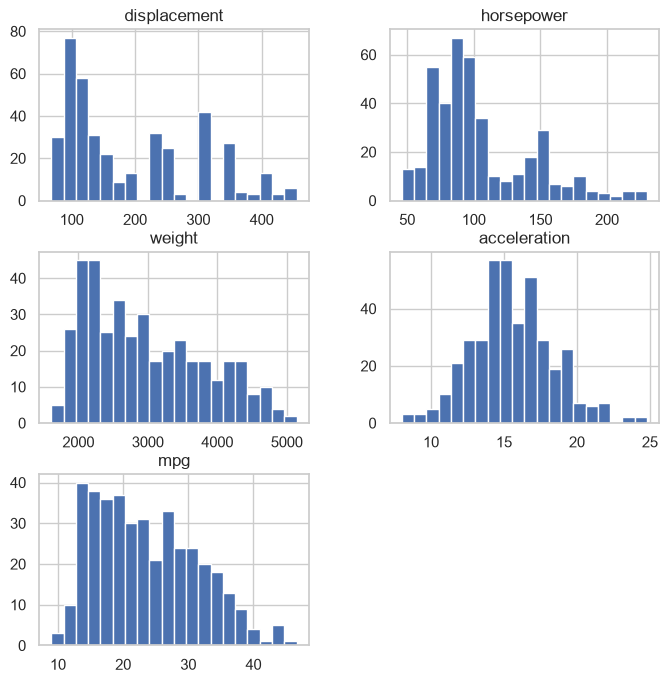

In [32]:
# Check distribution of numerical columns
cat_cols = ['cylinders', 'model_year', 'origin']
num_cols = df.select_dtypes(include=['float64', 'int64']).columns
num_cols = [col for col in num_cols if col not in cat_cols]

df[num_cols].hist(bins=20, figsize=(8,8))

Unique values in cylinders: [8 4 6 3 5]
Unique values in model_year: [70 71 72 73 74 75 76 77 78 79 80 81 82]
Unique values in origin: [1 3 2]


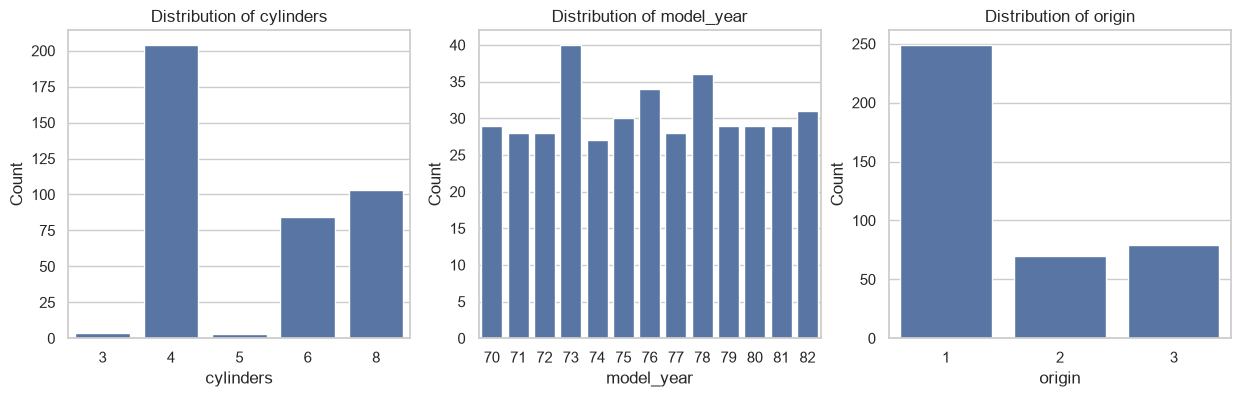

In [33]:
# Check unique values in categorical columns
for col in cat_cols:
    print(f"Unique values in {col}: {df[col].unique()}")

# Check distributin of unque values in categorical columns
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(x=col, data=df, ax=axs[i])
    axs[i].set_title(f'Distribution of {col}')
    axs[i].set_xlabel(col)
    axs[i].set_ylabel('Count')

### 2.4. Multivariate analysis

Explore interactions among multiple features

<Axes: >

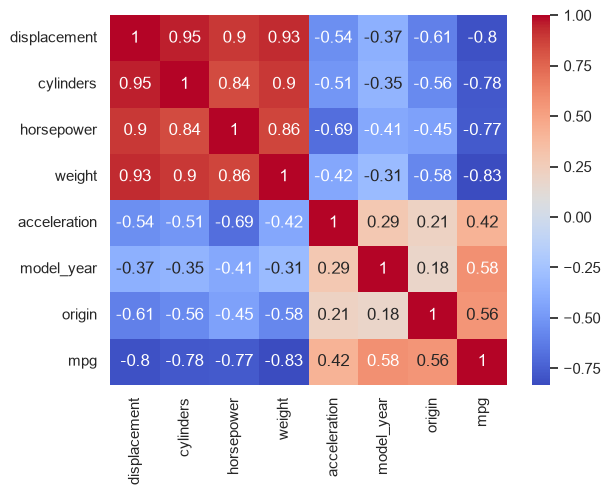

In [34]:
sns.heatmap(df.corr(), annot=True, cmap='coolwarm')

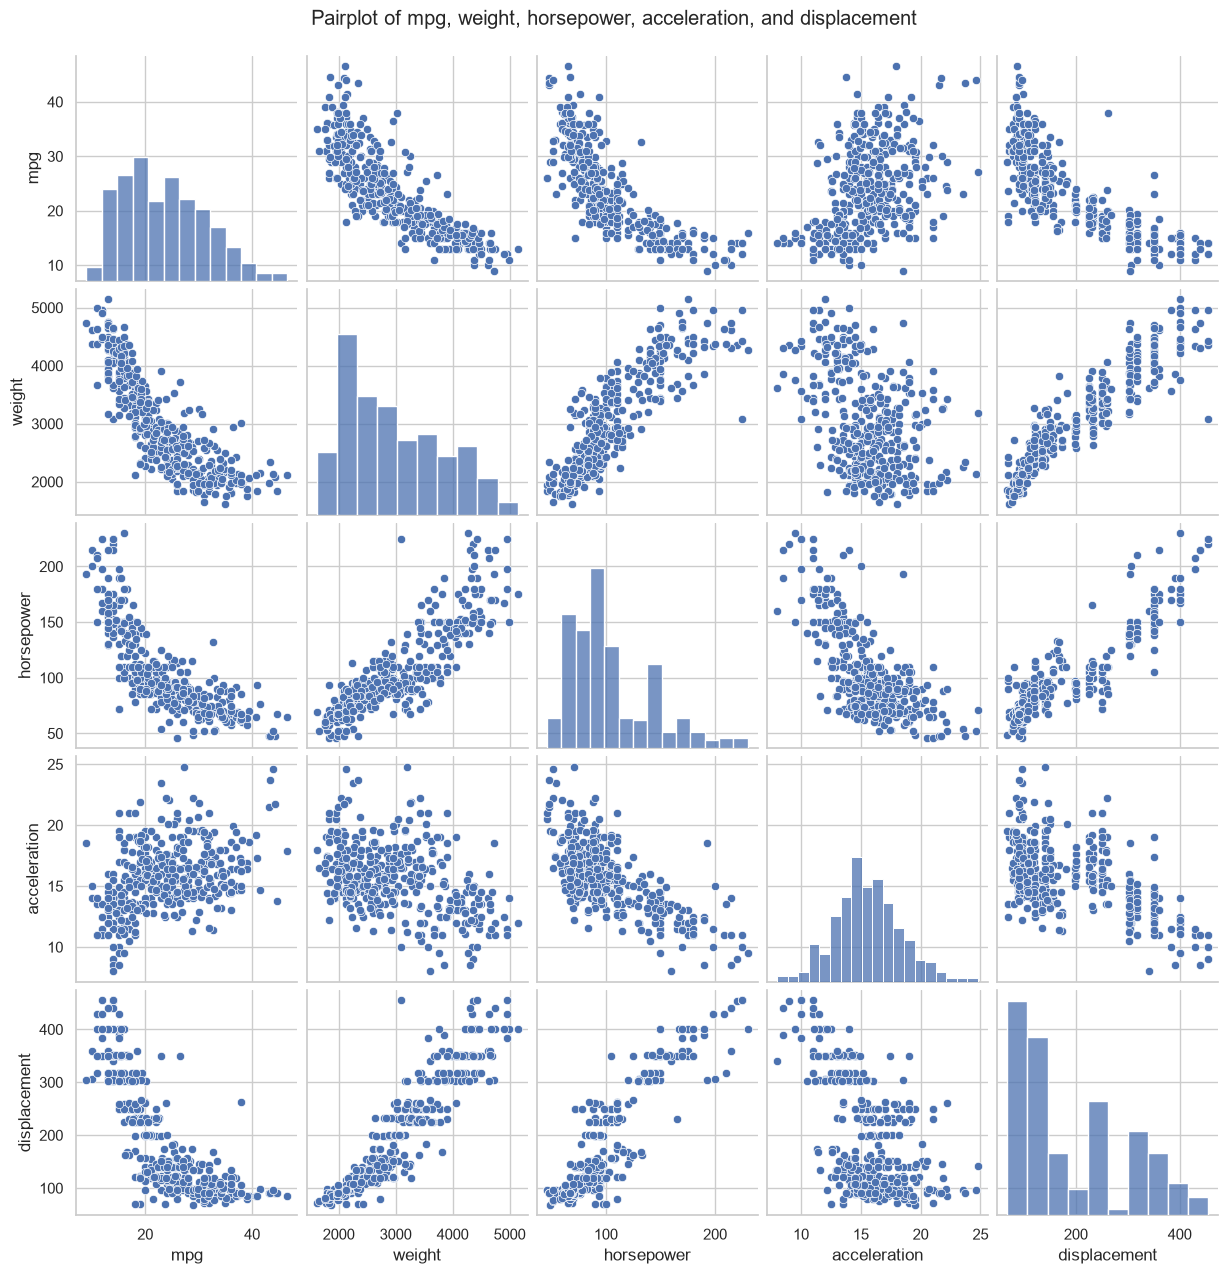

In [35]:
# (a) Pairplot of selected features
cols_pair = ['mpg', 'weight', 'horsepower', 'acceleration', 'displacement']
sns.pairplot(df[cols_pair].dropna(), diag_kind='hist')
plt.suptitle("Pairplot of mpg, weight, horsepower, acceleration, and displacement", y=1.02)
plt.show()

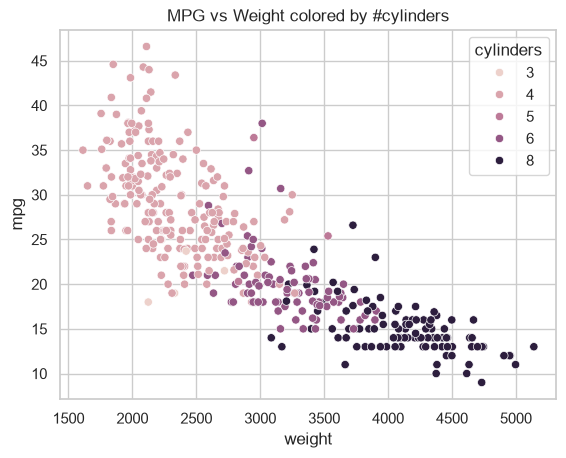

In [36]:
# (b) Scatter: mpg vs weight, colored by cylinders
sns.scatterplot(
    data=df,
    x='weight',
    y='mpg',
    hue='cylinders',
)
plt.title("MPG vs Weight colored by #cylinders")
plt.show()

## 3. Feature engineering

In [37]:
# TODO: Select features, make all features numeric and normalize values to the same range if necessary
from sklearn.preprocessing import StandardScaler

# Drop rows with missing values (horsepower has 6 missing values)
df_clean = df.dropna()

# Select numeric features and target
feature_cols = ['displacement', 'cylinders', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']
X_clean = df_clean[feature_cols]
y_clean = df_clean['mpg']

# Normalize features to the same scale
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_clean)

## 4. Model training

In [38]:
# TODO: Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_scaled, y_clean, test_size=0.2, random_state=42)

In [39]:
# TODO: Create a LinerRegression model instance from sklearn and fit the model
from sklearn.linear_model import LinearRegression

model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 1.48,-0.27,-0.5 ,..., 0.19, 2.94, 1.06]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,23.5
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](7,)","[37.72,17.21,15.17,..., 6.44, 4.42, 3.23]"


## 5. Evaluatation

In [40]:
#TODO: Predicting on the test set using the fitted model
y_pred = model.predict(X_test)
print("Predicted MPG (first 5):", y_pred[:5])

Predicted MPG (first 5): [32.88140046 29.55780381 21.36955005 16.79734409 12.4982001 ]


In [41]:
# TODO: Calculate evaluation metrics (MAE, MSE, RMSE, R2)
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print(f"MAE:  {mae:.3f}")
print(f"MSE:  {mse:.3f}")
print(f"RMSE: {rmse:.3f}")
print(f"R2:   {r2:.3f}")

MAE:  2.255
MSE:  8.198
RMSE: 2.863
R2:   0.848
